# Fase 2: ajuste de hiperparámetros

Los resultados se calculan con `python scripts/fase2_ajuste.py` (unos 40 minutos con 10 núcleos) y se guardan en `results/fase2_*.csv`. Este notebook solo los lee y los analiza.

**Método.** La búsqueda se hace por etapas, porque una rejilla completa (α × γ × intervalos × ε) sería unas 8 veces más cara:

- **Etapa A:** tasa de aprendizaje α (constante o decreciente) × factor de descuento γ.
- **Etapa B:** con el mejor α y γ de cada mercado y algoritmo, número de intervalos de tendencia × calendario de ε.
- **Etapa C:** con la mejor configuración, un entrenamiento de 6000 episodios para ver cuándo converge.

**Criterio.** Cada configuración se entrena con tres semillas. Se puntúa con la mediana del retorno en **100 series de validación**, promediada entre semillas. A igualdad, gana la que opera menos. Las series de test no se usan en ningún momento: son para la fase 3.

En los mapas de calor, el color es relativo dentro de cada panel (más oscuro = mejor) y el recuadro marca la configuración elegida.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

import rl_trader
from rl_trader.baselines import BASELINES
from rl_trader.evaluation import SEMILLA_VALIDACION, evaluar, generar_series
from rl_trader.experiments import HIPERPARAMETROS, elegir_mejores
from rl_trader.plots import (COLORES_ALGORITMO, EJE, NOMBRES_ALGORITMO, NOMBRES_MERCADO, TINTA_2,
                             aplicar_estilo, compacto, corto, mapa_calor)
from rl_trader.prices import GENERADORES

aplicar_estilo()
ROOT = Path(rl_trader.__file__).resolve().parent.parent
RESULTADOS, FIGURAS = ROOT / "results", ROOT / "figures"
MERCADOS, ALGORITMOS = list(NOMBRES_MERCADO), list(NOMBRES_ALGORITMO)

a = pd.read_csv(RESULTADOS / "fase2_etapa_a.csv")
b = pd.read_csv(RESULTADOS / "fase2_etapa_b.csv")
c = pd.read_csv(RESULTADOS / "fase2_etapa_c.csv")
curvas_c = pd.read_csv(RESULTADOS / "fase2_etapa_c_curvas.csv", dtype={"politica": str})


def tasa(alpha, omega):
    return f"α = {alpha:g}" if omega == 0 else f"α = 1/n^{omega:g}"


def calendario_eps(frac, final):
    return f"ε→{final:g} en {frac:.0%}"


for df in (a, b, c):
    df["tasa"] = [tasa(x, w) for x, w in zip(df["alpha"], df["omega"])]
    df["epsilon"] = [calendario_eps(f, e) for f, e in zip(df["frac_decaimiento"], df["eps_final"])]

mejor_a, mejor_b = elegir_mejores(a), elegir_mejores(b)
for df in (mejor_a, mejor_b):
    df["tasa"] = [tasa(x, w) for x, w in zip(df["alpha"], df["omega"])]
    df["epsilon"] = [calendario_eps(f, e) for f, e in zip(df["frac_decaimiento"], df["eps_final"])]
print(f"{len(a)} + {len(b)} + {len(c)} entrenamientos")

480 + 360 + 24 entrenamientos


## Etapa A: tasa de aprendizaje × γ

Mediana del retorno en validación (%), promediada entre las tres semillas. Configuración fija en esta etapa: 10 intervalos, ε de 1 a 0,01 durante el 70% de los 2000 episodios.

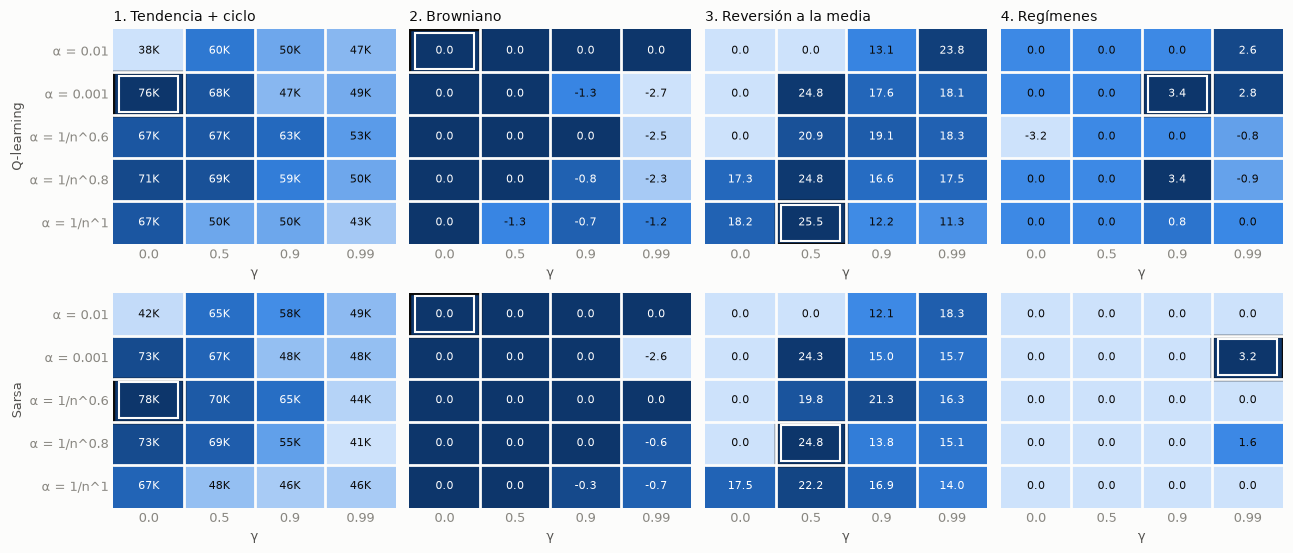

In [2]:
TASAS = ["α = 0.01", "α = 0.001", "α = 1/n^0.6", "α = 1/n^0.8", "α = 1/n^1"]
media_a = a.groupby(["mercado", "algoritmo", "tasa", "gamma"])["val_mediana"].mean()

fig, axes = plt.subplots(2, 4, figsize=(13, 5.6))
for i, algo in enumerate(ALGORITMOS):
    for j, m in enumerate(MERCADOS):
        tabla = media_a.loc[(m, algo)].unstack("gamma").reindex(TASAS)
        elegida = mejor_a[(mejor_a.mercado == m) & (mejor_a.algoritmo == algo)].iloc[0]
        mapa_calor(axes[i, j], tabla, destacar=(TASAS.index(elegida.tasa), list(tabla.columns).index(elegida.gamma)))
        axes[i, j].set_xlabel("γ")
        if i == 0:
            axes[i, j].set_title(NOMBRES_MERCADO[m], loc="left")
        if j > 0:
            axes[i, j].set_yticklabels([])
    axes[i, 0].set_ylabel(NOMBRES_ALGORITMO[algo])
fig.tight_layout()
fig.savefig(FIGURAS / "fase2_etapa_a.png", dpi=200)
plt.show()

## Etapa B: intervalos de tendencia × calendario de ε

Con el α y el γ elegidos en la etapa A para cada mercado y algoritmo. "ε→0,01 en 30%" significa que ε baja de 1 a 0,01 durante el primer 30% de los episodios y luego se queda fijo.

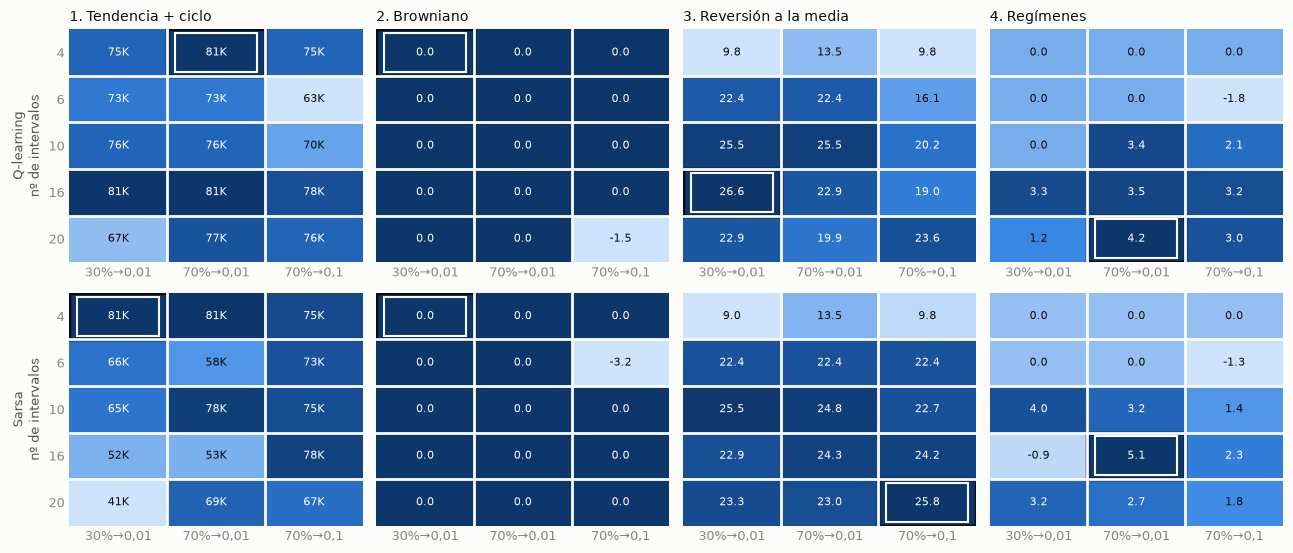

In [3]:
EPS = ["ε→0.01 en 30%", "ε→0.01 en 70%", "ε→0.1 en 70%"]
media_b = b.groupby(["mercado", "algoritmo", "n_intervalos", "epsilon"])["val_mediana"].mean()

fig, axes = plt.subplots(2, 4, figsize=(13, 5.6))
for i, algo in enumerate(ALGORITMOS):
    for j, m in enumerate(MERCADOS):
        tabla = media_b.loc[(m, algo)].unstack("epsilon")[EPS]
        elegida = mejor_b[(mejor_b.mercado == m) & (mejor_b.algoritmo == algo)].iloc[0]
        mapa_calor(axes[i, j], tabla, destacar=(list(tabla.index).index(elegida.n_intervalos), EPS.index(elegida.epsilon)))
        axes[i, j].set_xticklabels(["30%→0,01", "70%→0,01", "70%→0,1"])
        if i == 0:
            axes[i, j].set_title(NOMBRES_MERCADO[m], loc="left")
        if j > 0:
            axes[i, j].set_yticklabels([])
    axes[i, 0].set_ylabel(f"{NOMBRES_ALGORITMO[algo]}\nnº de intervalos")
fig.tight_layout()
fig.savefig(FIGURAS / "fase2_etapa_b.png", dpi=200)
plt.show()

## Configuraciones elegidas

La columna *fase 1* es la configuración por defecto de la primera pasada (α = 1/n^0,6, γ = 0,9, 10 intervalos, ε→0,01 en 70%), medida aquí con las mismas 100 series de validación. *sd semillas* es la desviación típica de la mediana de validación entre las tres semillas de la configuración elegida: da una idea del ruido de la propia elección.

In [4]:
por_defecto = (a[(a.alpha == 1.0) & (a.omega == 0.6) & (a.gamma == 0.9)]
               .groupby(["mercado", "algoritmo"])["val_mediana"].mean().rename("fase 1"))
ruido = b.groupby(["mercado", "algoritmo", *HIPERPARAMETROS])["val_mediana"].std().rename("sd semillas")
elegidas = (mejor_b.join(ruido, on=["mercado", "algoritmo", *HIPERPARAMETROS])
            .join(por_defecto, on=["mercado", "algoritmo"]))
elegidas["mercado"] = pd.Categorical(elegidas["mercado"], MERCADOS, ordered=True)
elegidas = elegidas.sort_values(["mercado", "algoritmo"])
elegidas["gamma"] = [f"{g:g}" for g in elegidas["gamma"]]
columnas = ["mercado", "algoritmo", "tasa", "gamma", "n_intervalos", "epsilon",
            "val_mediana", "sd semillas", "fase 1", "val_operaciones"]
print(elegidas[columnas].to_string(index=False, float_format=corto))

  mercado algoritmo        tasa gamma  n_intervalos       epsilon  val_mediana  sd semillas  fase 1  val_operaciones
    ciclo qlearning   α = 0.001     0             4 ε→0.01 en 70%          81K          0.0     63K             31.3
    ciclo     sarsa α = 1/n^0.6     0             4 ε→0.01 en 30%          81K          0.0     65K             31.3
browniano qlearning    α = 0.01     0             4 ε→0.01 en 30%          0.0          0.0     0.0              0.0
browniano     sarsa    α = 0.01     0             4 ε→0.01 en 30%          0.0          0.0     0.0              0.0
reversion qlearning   α = 1/n^1   0.5            16 ε→0.01 en 30%         26.6          5.6    19.1             30.7
reversion     sarsa α = 1/n^0.8   0.5            20  ε→0.1 en 70%         25.8          1.3    21.3             33.1
regimenes qlearning   α = 0.001   0.9            20 ε→0.01 en 70%          4.2          2.0     0.0             21.8
regimenes     sarsa   α = 0.001  0.99            16 ε→0.01 en 70

## Etapa C: convergencia

Entrenamientos de 6000 episodios con la configuración elegida. Para cada mercado se muestra la mediana del retorno en las 100 series de validación, cada 200 episodios y promediada entre semillas. La línea gris es buy & hold en esas mismas series.

**Episodio de estabilización:** el primer control a partir del cual la política efectiva ya no cambia. La política efectiva es la de estar dentro o fuera en cada estado; si el agente no compra nunca, los estados con activo se ignoran.

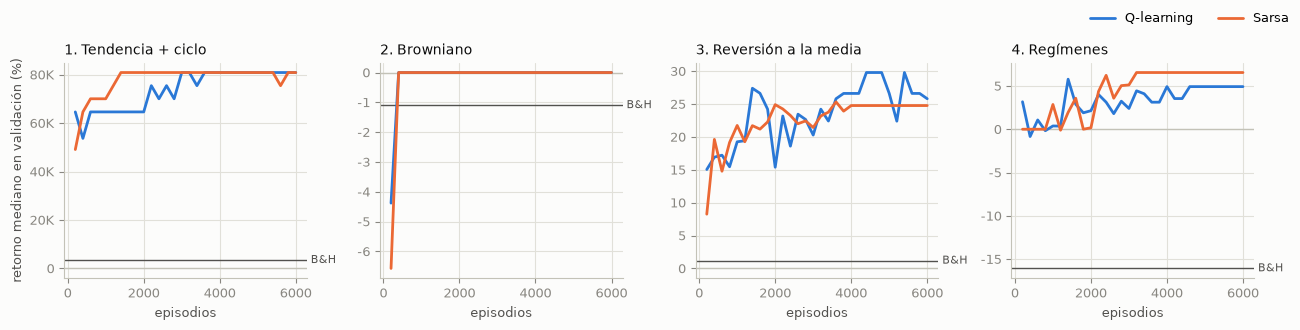

  mercado algoritmo episodio_estable (por semilla)  segundos hasta estable (media)  val @2000  val @4000  val @6000
    ciclo     sarsa             1200 / 1400 / 5800                            38.6        81K        81K        81K
    ciclo qlearning             3600 / 2600 / 3000                            42.0        65K        81K        81K
reversion qlearning             3200 / 6000 / 6000                            67.9       15.4       26.6       25.8
reversion     sarsa             4200 / 4000 / 4200                            52.8       24.9       24.8       24.8
regimenes     sarsa             3200 / 2200 / 2800                            34.0        0.2        6.5        6.5
regimenes qlearning             3600 / 4600 / 4000                            53.0        2.1        4.9        4.9
browniano qlearning                200 / 400 / 200                             3.4        0.0        0.0        0.0
browniano     sarsa                200 / 200 / 400                      

In [5]:
curvas_c = curvas_c.merge(c[["run", "mercado", "algoritmo", "seed", "episodio_estable"]], on="run")

fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for ax, m in zip(axes, MERCADOS):
    val = generar_series(GENERADORES[m], 100, SEMILLA_VALIDACION)
    bh = evaluar(BASELINES["buy_and_hold"](), val)["retorno_pct"].median()
    ax.axhline(0, color=EJE, lw=1)
    ax.axhline(bh, color=TINTA_2, lw=1)
    ax.text(1.0, bh, " B&H", transform=ax.get_yaxis_transform(), va="center", color=TINTA_2, fontsize=8)
    for algo in ALGORITMOS:
        d = curvas_c[(curvas_c.mercado == m) & (curvas_c.algoritmo == algo)]
        media = d.groupby("episodio")["retorno_mediana_pct"].mean()
        ax.plot(media.index, media.values, color=COLORES_ALGORITMO[algo], label=NOMBRES_ALGORITMO[algo])
    ax.set_title(NOMBRES_MERCADO[m], loc="left")
    ax.set_xlabel("episodios")
    ax.yaxis.set_major_formatter(FuncFormatter(compacto))
axes[0].set_ylabel("retorno mediano en validación (%)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(FIGURAS / "fase2_convergencia.png", dpi=200)
plt.show()

filas = []
for (m, algo), d in curvas_c.groupby(["mercado", "algoritmo"], sort=False):
    estable = d.groupby("seed")["episodio_estable"].first()
    seg = [d[(d.seed == s) & (d.episodio == e)]["segundos"].iloc[0] for s, e in estable.items()]
    por_ep = d.groupby("episodio")["retorno_mediana_pct"].mean()
    filas.append({"mercado": m, "algoritmo": algo,
                  "episodio_estable (por semilla)": " / ".join(str(e) for e in estable),
                  "segundos hasta estable (media)": np.mean(seg),
                  "val @2000": por_ep.loc[2000], "val @4000": por_ep.loc[4000], "val @6000": por_ep.loc[6000]})
print(pd.DataFrame(filas).to_string(index=False, float_format=corto))

## Conclusiones

Las cifras son medianas del retorno en validación, promediadas entre semillas. La comparación de referencia es la configuración por defecto de la fase 1.

**Configuración para la fase 3.** La de la tabla de configuraciones elegidas, con **4000 episodios**: es donde se estabilizan las curvas de todos los mercados.

**Tendencia + ciclo.** El mejor γ es **0** en ambos algoritmos: +80.900%, frente a unos +64.000% con la configuración de la fase 1.

- Tiene sentido. La señal de un paso es enorme y el agente no influye en la tendencia. Con γ alto solo se añade ruido al objetivo (el ruido es del 10% por paso).
- Con γ = 0, Q-learning y Sarsa son **el mismo algoritmo**, porque los dos usan como objetivo solo la recompensa. Por eso las seis ejecuciones acaban en la misma política, aunque el α elegido sea distinto.
- Bastan 4 intervalos. La política es momentum con histéresis: compra solo con tendencia muy positiva (por encima de +10,6%) y no vende hasta que la tendencia es muy negativa.

**Browniano.** Ninguna configuración supera a quedarse fuera. Las que operan (sobre todo con γ = 0,99) pierden hasta un 2,7%, y buy & hold queda en −1,1% en estas series.

- Muchas configuraciones empatan a 0, así que la elegida (α = 0,01, γ = 0) es arbitraria. Da igual: el agente no opera.

**Reversión a la media.** El mejor γ es **0,5** (≈ +26%, frente a +19–21% con γ = 0,9).

- Con γ = 0 y α constante, el agente a menudo no llega a operar.
- Los intervalos finos (10 a 20) son claramente mejores que 4 o 6 (+13% con 4). La señal se concentra en las tendencias más extremas, y hace falta resolución para aislarlas.
- La política aprendida es contrarian con mucha histéresis: compra solo en los 2–3 intervalos más bajistas y mantiene hasta los más alcistas.

**Regímenes.** Es lo que más cambia respecto a la fase 1.

- Con α constante pequeño (0,001), γ ≥ 0,9 y 16–20 intervalos, los agentes pasan de no operar (0%) a **+4–5%**. Buy & hold queda en −16%.
- La política tiene una lectura clara. Compra solo con una tendencia positiva moderada (+0,3% a +0,9%). Una vez dentro, mantiene salvo ante movimientos extremos, en cualquier dirección.
- Es decir, usa el **tamaño** de la tendencia como aproximación de la volatilidad: tendencias suaves para el régimen alcista tranquilo y movimientos grandes para el bajista volátil.
- **Cautela:** la ganancia es pequeña, del orden del ruido entre semillas (±2 puntos). Además, se eligió entre 35 configuraciones, así que la cifra de validación es optimista. El test de la fase 3 dirá si se mantiene.

**Convergencia.** Con las configuraciones elegidas, las curvas se estabilizan:

- en torno a los 2000 episodios (ciclo con Sarsa) o los 3000 (ciclo con Q-learning);
- en torno a los 4000 en reversión y regímenes, que aprenden más despacio por el α constante pequeño;
- en 200–400 episodios en el browniano.

La política completa a veces sigue cambiando hasta el final. Pasa en estados poco visitados, que apenas afectan al resultado.

**Q-learning frente a Sarsa.** Fuera del caso γ = 0, quedan muy cerca: Sarsa algo mejor en regímenes y Q-learning en reversión. Las diferencias están dentro del ruido.

**Limitaciones del ajuste.**

- La búsqueda por etapas no explora todas las interacciones. Por ejemplo, el número de intervalos solo se probó con el mejor γ.
- Con tres semillas y 100 series, las diferencias pequeñas entre configuraciones no son significativas.
